<a href="https://colab.research.google.com/github/arpana62/Image-processing-lab/blob/main/Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter x1: 3
Enter y1: 6
Enter x2: 18
Enter xy2: 12

--- Direct Line Equation Method ---
Starting point: (3, 6)
Ending point: (18, 12)
Slope: 0.4
Y-intercept: 4.8
Case: Shallow line.

x = 3 y = 6.0 pixels -> (3, 6)
x = 4 y = 6.4 pixels -> (4, 6)
x = 5 y = 6.8 pixels -> (5, 7)
x = 6 y = 7.2 pixels -> (6, 7)
x = 7 y = 7.6 pixels -> (7, 8)
x = 8 y = 8.0 pixels -> (8, 8)
x = 9 y = 8.4 pixels -> (9, 8)
x = 10 y = 8.8 pixels -> (10, 9)
x = 11 y = 9.2 pixels -> (11, 9)
x = 12 y = 9.600000000000001 pixels -> (12, 10)
x = 13 y = 10.0 pixels -> (13, 10)
x = 14 y = 10.4 pixels -> (14, 10)
x = 15 y = 10.8 pixels -> (15, 11)
x = 16 y = 11.2 pixels -> (16, 11)
x = 17 y = 11.600000000000001 pixels -> (17, 12)
x = 18 y = 12.0 pixels -> (18, 12)


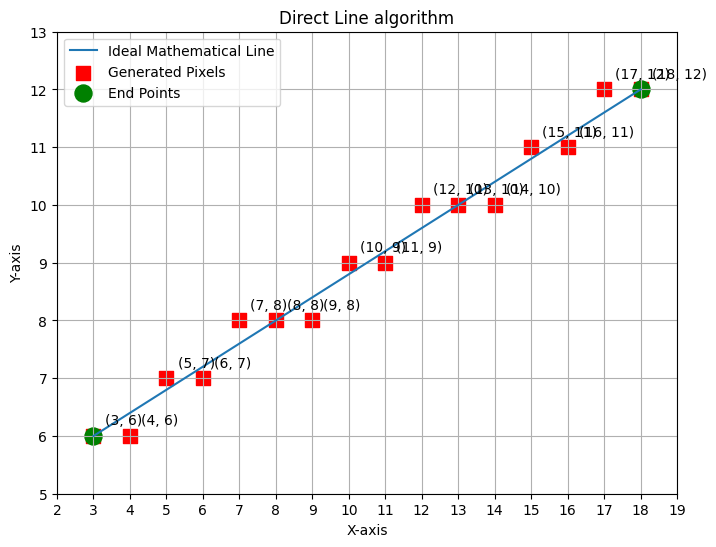

In [2]:
#Direct Line Equation
import matplotlib.pyplot as plt
def direct_line(x1, y1, x2, y2):
    pixels = []
    print("\n--- Direct Line Equation Method ---")
    print("Starting point:", (x1, y1))
    print("Ending point:", (x2, y2))

    dx = x2 - x1
    dy = y2 - y1

    # Vertical line
    if dx == 0:
        print("Case: Vertical line.")
        print("Slope is undefined.\n")

        start_y = min(y1, y2)
        end_y = max(y1, y2)

        for y in range(start_y, end_y + 1):
            pixels.append((x1, y))
            print("x =", x1, "y =", y, "pixels ->", (x1, y))

    else:
        # Calculate slope and y-intercept
        m = dy / dx
        b = y1 - m * x1

        print("Slope:", m)
        print("Y-intercept:", b)

        # Horizontal or shallow line
        if abs(m) <= 1:
            print("Case: Shallow line.\n")

            start_x = min(x1, x2)
            end_x = max(x1, x2)

            for x in range(start_x, end_x + 1):
                y = m * x + b
                round_y = round(y)

                pixels.append((x, round_y))

                print(
                    "x =", x,
                    "y =", y,
                    "pixels ->", (x, round_y)
                )

        # Steep line
        else:
            print("Case: Steep line.\n")

            start_y = min(y1, y2)
            end_y = max(y1, y2)
            for y in range(start_y, end_y + 1):
                x = (y - b) / m
                round_x = round(x)
                pixels.append((round_x, y))

                print(
                    "y =", y,
                    "x =", x,
                    "pixels ->", (round_x, y)
                )

    return pixels
x1=int(input("Enter x1: "))
y1=int(input("Enter y1: "))

x2=int(input("Enter x2: "))
y2=int(input("Enter xy2: "))
#callimg function
pixels=direct_line(x1,y1,x2,y2)
# Plotting

x_pixels = [p[0] for p in pixels]
y_pixels = [p[1] for p in pixels]

plt.figure(figsize=(8, 6))

# Ideal mathematical line
plt.plot(
    [x1, x2],
    [y1, y2],
    label="Ideal Mathematical Line"
)

# Generated pixels
plt.scatter(
    x_pixels,
    y_pixels,
    s=100,
    marker="s",
    color="red",
    label="Generated Pixels"
)

# End points
plt.scatter(
    [x1, x2],
    [y1, y2],
    s=150,
    marker="o",
    color="green",
    label="End Points"
)

# Label each generated pixel
for x, y in pixels:
    plt.annotate(
        f"({x}, {y})",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

# Axis settings
plt.xticks(range(min(x1, x2) - 1, max(x1, x2) + 2))
plt.yticks(range(min(y1, y2) - 1, max(y1, y2) + 2))

plt.grid(True)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Direct Line algorithm")
plt.legend()

plt.show()


Enter x1: 1
Enter y1: 1
Enter x2: 4
Enter y2: 3

--- DDA Line Drawing Algorithm ---
Starting point: (1, 1)
Ending point: (4, 3)
dx = 3
dy = 2
Steps = 3
X increment: 1.0
Y increment: 0.6666666666666666

Generated Pixels:

x = 1 y = 1 pixels -> (1, 1)
x = 2.0 y = 1.6666666666666665 pixels -> (2, 2)
x = 3.0 y = 2.333333333333333 pixels -> (3, 2)
x = 4.0 y = 2.9999999999999996 pixels -> (4, 3)


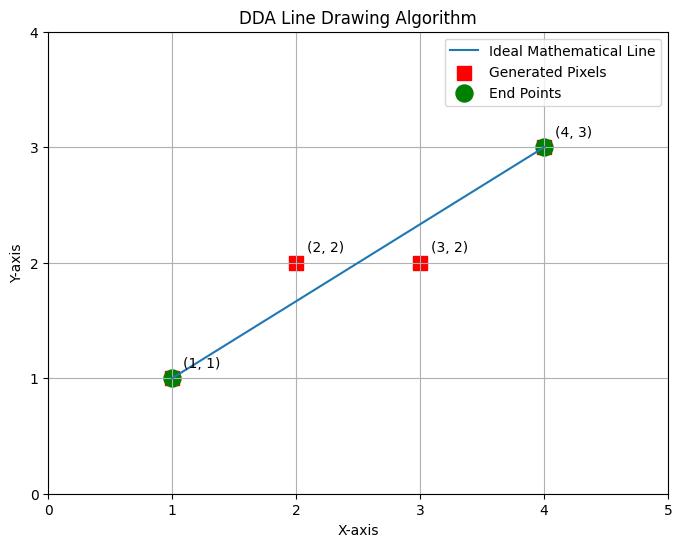

In [ ]:
# DDA Line Drawing Algorithm

import matplotlib.pyplot as plt


def dda_line(x1, y1, x2, y2):
    pixels = []

    print("\n--- DDA Line Drawing Algorithm ---")
    print("Starting point:", (x1, y1))
    print("Ending point:", (x2, y2))

    dx = x2 - x1
    dy = y2 - y1

    # Calculate number of steps
    steps = max(abs(dx), abs(dy))

    print("dx =", dx)
    print("dy =", dy)
    print("Steps =", steps)

    # Calculate increments
    if steps == 0:
        pixels.append((x1, y1))
        print("Single point:", (x1, y1))
        return pixels

    x_increment = dx / steps
    y_increment = dy / steps

    print("X increment:", x_increment)
    print("Y increment:", y_increment)
    print("\nGenerated Pixels:\n")

    x = x1
    y = y1

    for i in range(steps + 1):
        round_x = round(x)
        round_y = round(y)

        pixels.append((round_x, round_y))

        print(
            "x =", x,
            "y =", y,
            "pixels ->", (round_x, round_y)
        )

        x = x + x_increment
        y = y + y_increment

    return pixels


# Input
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))

x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))


# Calling function
pixels = dda_line(x1, y1, x2, y2)


# Plotting

x_pixels = [p[0] for p in pixels]
y_pixels = [p[1] for p in pixels]

plt.figure(figsize=(8, 6))

# Ideal mathematical line
plt.plot(
    [x1, x2],
    [y1, y2],
    label="Ideal Mathematical Line"
)

# Generated pixels
plt.scatter(
    x_pixels,
    y_pixels,
    s=100,
    marker="s",
    color="red",
    label="Generated Pixels"
)

# End points
plt.scatter(
    [x1, x2],
    [y1, y2],
    s=150,
    marker="o",
    color="green",
    label="End Points"
)

# Label each pixel
for x, y in pixels:
    plt.annotate(
        f"({x}, {y})",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

# Axis settings
plt.xticks(range(min(x1, x2) - 1, max(x1, x2) + 2))
plt.yticks(range(min(y1, y2) - 1, max(y1, y2) + 2))

plt.grid(True)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("DDA Line Drawing Algorithm")
plt.legend()

plt.show()

Enter x1: 5
Enter y1: 6
Enter x2: 13
Enter y2: 10

--- Bresenham's Line Drawing Algorithm ---
Starting point: (5, 6)
Ending point: (13, 10)
dx = 8
dy = 4
Case: Shallow line.
Initial decision parameter: 0

Generated Pixels:

x = 5 y = 6 p = 0 pixels -> (5, 6)
x = 6 y = 7 p = -8 pixels -> (6, 7)
x = 7 y = 7 p = 0 pixels -> (7, 7)
x = 8 y = 8 p = -8 pixels -> (8, 8)
x = 9 y = 8 p = 0 pixels -> (9, 8)
x = 10 y = 9 p = -8 pixels -> (10, 9)
x = 11 y = 9 p = 0 pixels -> (11, 9)
x = 12 y = 10 p = -8 pixels -> (12, 10)
x = 13 y = 10 p = 0 pixels -> (13, 10)


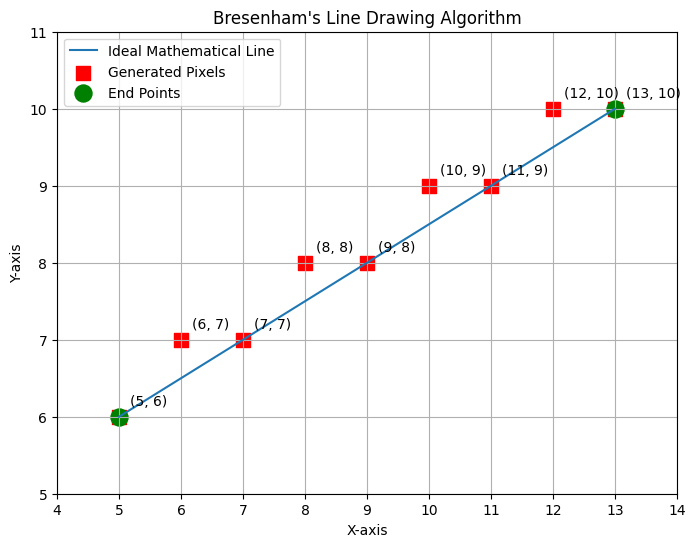

In [ ]:
# Bresenham's Line Drawing Algorithm

import matplotlib.pyplot as plt


def bresenham_line(x1, y1, x2, y2):
    pixels = []

    print("\n--- Bresenham's Line Drawing Algorithm ---")
    print("Starting point:", (x1, y1))
    print("Ending point:", (x2, y2))

    dx = abs(x2 - x1)
    dy = abs(y2 - y1)

    sx = 1 if x2 >= x1 else -1
    sy = 1 if y2 >= y1 else -1

    print("dx =", dx)
    print("dy =", dy)

    x = x1
    y = y1

    # Shallow line
    if dx >= dy:
        print("Case: Shallow line.")

        p = 2 * dy - dx

        print("Initial decision parameter:", p)
        print("\nGenerated Pixels:\n")

        for i in range(dx + 1):

            pixels.append((x, y))

            print(
                "x =", x,
                "y =", y,
                "p =", p,
                "pixels ->", (x, y)
            )

            if p >= 0:
                y = y + sy
                p = p + 2 * (dy - dx)
            else:
                p = p + 2 * dy

            x = x + sx

    # Steep line
    else:
        print("Case: Steep line.")

        p = 2 * dx - dy

        print("Initial decision parameter:", p)
        print("\nGenerated Pixels:\n")

        for i in range(dy + 1):

            pixels.append((x, y))

            print(
                "x =", x,
                "y =", y,
                "p =", p,
                "pixels ->", (x, y)
            )

            if p >= 0:
                x = x + sx
                p = p + 2 * (dx - dy)
            else:
                p = p + 2 * dx

            y = y + sy

    return pixels


# Input
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))

x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))


# Calling function
pixels = bresenham_line(x1, y1, x2, y2)


# Plotting

x_pixels = [p[0] for p in pixels]
y_pixels = [p[1] for p in pixels]

plt.figure(figsize=(8, 6))

# Ideal mathematical line
plt.plot(
    [x1, x2],
    [y1, y2],
    label="Ideal Mathematical Line"
)

# Generated pixels
plt.scatter(
    x_pixels,
    y_pixels,
    s=100,
    marker="s",
    color="red",
    label="Generated Pixels"
)

# End points
plt.scatter(
    [x1, x2],
    [y1, y2],
    s=150,
    marker="o",
    color="green",
    label="End Points"
)

# Label each generated pixel
for x, y in pixels:
    plt.annotate(
        f"({x}, {y})",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

# Axis settings
plt.xticks(range(min(x1, x2) - 1, max(x1, x2) + 2))
plt.yticks(range(min(y1, y2) - 1, max(y1, y2) + 2))

plt.grid(True)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Bresenham's Line Drawing Algorithm")
plt.legend()

plt.show()

Enter center x: 0
Enter center y: 0
Enter radius: 9

--- Bresenham Circle Drawing Algorithm ---
Center: (0, 0)
Radius: 9
Initial decision parameter: -15

Generated Pixels:

x = 0 y = 9 p = -15 pixels -> [(0, 9), (0, 9), (0, -9), (0, -9), (9, 0), (-9, 0), (9, 0), (-9, 0)]
x = 1 y = 9 p = -9 pixels -> [(1, 9), (-1, 9), (1, -9), (-1, -9), (9, 1), (-9, 1), (9, -1), (-9, -1)]
x = 2 y = 9 p = 1 pixels -> [(2, 9), (-2, 9), (2, -9), (-2, -9), (9, 2), (-9, 2), (9, -2), (-9, -2)]
x = 3 y = 8 p = -17 pixels -> [(3, 8), (-3, 8), (3, -8), (-3, -8), (8, 3), (-8, 3), (8, -3), (-8, -3)]
x = 4 y = 8 p = 1 pixels -> [(4, 8), (-4, 8), (4, -8), (-4, -8), (8, 4), (-8, 4), (8, -4), (-8, -4)]
x = 5 y = 7 p = -5 pixels -> [(5, 7), (-5, 7), (5, -7), (-5, -7), (7, 5), (-7, 5), (7, -5), (-7, -5)]
x = 6 y = 7 p = 21 pixels -> [(6, 7), (-6, 7), (6, -7), (-6, -7), (7, 6), (-7, 6), (7, -6), (-7, -6)]


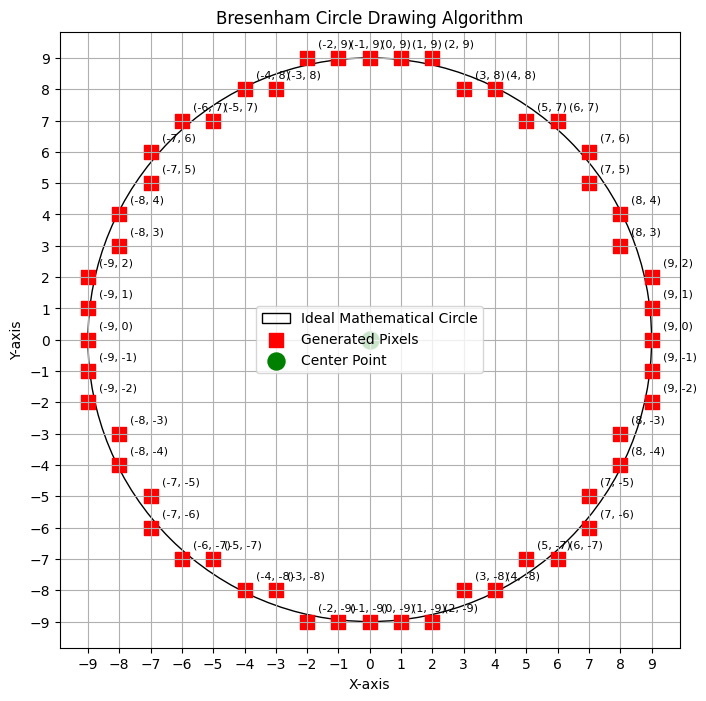

In [4]:
# Bresenham's Circle Drawing Algorithm
import matplotlib.pyplot as plt
def bresenham_circle(xc, yc, r):

    pixels = []

    print("\n--- Bresenham Circle Drawing Algorithm ---")
    print("Center:", (xc, yc))
    print("Radius:", r)

    x = 0
    y = r

    # Initial decision parameter
    p = 3 - 2 * r

    print("Initial decision parameter:", p)
    print("\nGenerated Pixels:\n")

    while x <= y:

        # 8 symmetric points
        points = [
            (xc + x, yc + y),
            (xc - x, yc + y),
            (xc + x, yc - y),
            (xc - x, yc - y),
            (xc + y, yc + x),
            (xc - y, yc + x),
            (xc + y, yc - x),
            (xc - y, yc - x)
        ]

        # Add points
        for point in points:
            if point not in pixels:
                pixels.append(point)

        print(
            "x =", x,
            "y =", y,
            "p =", p,
            "pixels ->", points
        )

        # Decision parameter
        if p < 0:
            p = p + 4 * x + 6

        else:
            p = p + 4 * (x - y) + 10
            y = y - 1

        x = x + 1

    return pixels


# Input

xc = int(input("Enter center x: "))
yc = int(input("Enter center y: "))
r = int(input("Enter radius: "))


# Calling function

pixels = bresenham_circle(xc, yc, r)


# Plotting

x_pixels = [p[0] for p in pixels]
y_pixels = [p[1] for p in pixels]

plt.figure(figsize=(8, 8))


# Ideal mathematical circle

circle = plt.Circle(
    (xc, yc),
    r,
    fill=False,
    label="Ideal Mathematical Circle"
)

plt.gca().add_patch(circle)


# Generated pixels

plt.scatter(
    x_pixels,
    y_pixels,
    s=100,
    marker="s",
    color="red",
    label="Generated Pixels"
)


# Center point

plt.scatter(
    xc,
    yc,
    s=150,
    marker="o",
    color="green",
    label="Center Point"
)


# Label each generated pixel

for x, y in pixels:
    plt.annotate(
        f"({x}, {y})",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=8
    )


# Axis settings

plt.xticks(
    range(xc - r - 1, xc + r + 2)
)

plt.yticks(
    range(yc - r - 1, yc + r + 2)
)

plt.grid(True)

plt.xlabel("X-axis")
plt.ylabel("Y-axis")

plt.title("Bresenham Circle Drawing Algorithm")

plt.legend()

plt.axis("equal")

plt.show()